# Banking App Review Intelligence
What do customers complain about in Indian banking apps, how do the banks compare, and what should a product team fix first? Data: 37,459 public Google Play reviews of five apps (SBI YONO, HDFC, ICICI iMobile, Kotak, Federal), 1 Jul - 9 Oct 2026.

## Cleaning the data
Removes duplicates, empty text, reviews under 4 words and non-English text. Raw 37,459 reviews fall to 16,313, mostly because 56% of reviews were very short ("good app", "nice"). The log below shows rows left after each step.

## Satisfaction across all reviews
Uses all reviews (no length filter) to compare satisfaction fairly. Federal has the lowest share of 1-2 star reviews (11.8%); the other four sit between 31% and 35%.


In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/reviews_raw.csv", parse_dates=["at"])
log = [("raw reviews", len(df))]

# 1. remove duplicates
df = df.drop_duplicates(subset="reviewId")
log.append(("after removing duplicates", len(df)))

# 2. remove empty text
df = df.dropna(subset=["content"])
df["content"] = df["content"].str.strip()
df = df[df["content"].str.len() > 0]
log.append(("after removing empty text", len(df)))

# 3. remove very short reviews ("good", "ok", emoji-only)
df["word_count"] = df["content"].str.split().str.len()
df = df[df["word_count"] >= 4]
log.append(("after removing reviews under 4 words", len(df)))

# 4. keep mostly-English text (drops Hindi/other scripts; Hinglish stays)
def ascii_share(s):
    return sum(c.isascii() for c in s) / len(s)

df = df[df["content"].apply(ascii_share) > 0.9]
log.append(("after keeping mostly-English text", len(df)))

# helper columns
df["month"] = df["at"].dt.to_period("M").astype(str)
df["text_clean"] = df["content"].str.lower()

pd.DataFrame(log, columns=["step", "rows"])


,step,rows
0,raw reviews,37459
1,after removing duplicates,37459
2,after removing empty text,37459
3,after removing reviews under 4 words,16616
4,after keeping mostly-English text,16313


In [2]:
summary = df.groupby("bank").agg(
    reviews=("reviewId", "count"),
    avg_rating=("score", "mean"),
    negative=("score", lambda s: (s <= 2).sum()),
)
summary["negative_pct"] = (summary["negative"] / summary["reviews"] * 100).round(1)
summary["avg_rating"] = summary["avg_rating"].round(2)
summary


,reviews,avg_rating,negative,negative_pct
bank,,,,
Federal,1398,3.84,371,26.5
HDFC,4301,2.24,2883,67.0
ICICI,4525,2.47,2726,60.2
Kotak,1052,2.08,749,71.2
SBI YONO,5037,2.62,2853,56.6


In [3]:
df["month"] = df["at"].dt.to_period("M").astype(str)
df["text_clean"] = df["content"].str.lower()

pd.DataFrame(log, columns=["step", "rows"])


,step,rows
0,raw reviews,37459
1,after removing duplicates,37459
2,after removing empty text,37459
3,after removing reviews under 4 words,16616
4,after keeping mostly-English text,16313


## 3. Bias check: short vs long reviews
Short reviews are almost all happy ones (4.4-4.8 stars), so the cleaned data is more negative than the full user base. The word-limit test shows the "% negative" figure depends on the cutoff (53% at 3 words, 62% at 5), so percentages are always reported as shares of written complaints.

In [4]:
raw = pd.read_csv("../data/raw/reviews_raw.csv")
raw["short"] = raw["content"].fillna("").str.split().str.len() < 4

check = raw.groupby("bank").agg(
    raw_avg_rating=("score", "mean"),
    short_share=("short", "mean"),
).round(2)
check["avg_rating_short"] = raw[raw["short"]].groupby("bank")["score"].mean().round(2)
check["avg_rating_kept"] = raw[~raw["short"]].groupby("bank")["score"].mean().round(2)
check

,raw_avg_rating,short_share,avg_rating_short,avg_rating_kept
bank,,,,
Federal,4.44,0.61,4.81,3.85
HDFC,3.60,0.62,4.44,2.26
ICICI,3.54,0.54,4.45,2.48
Kotak,3.53,0.60,4.51,2.09
SBI YONO,3.49,0.47,4.43,2.63


In [5]:
raw = pd.read_csv("../data/raw/reviews_raw.csv", parse_dates=["at"])
raw = raw.drop_duplicates(subset="reviewId")

satisfaction = raw.groupby("bank").agg(
    reviews=("reviewId", "count"),
    avg_rating=("score", "mean"),
    pct_1_2_star=("score", lambda s: (s <= 2).mean() * 100),
    pct_4_5_star=("score", lambda s: (s >= 4).mean() * 100),
).round(1)
satisfaction

,reviews,avg_rating,pct_1_2_star,pct_4_5_star
bank,,,,
Federal,3649,4.4,11.8,86.8
HDFC,11444,3.6,31.3,64.1
ICICI,9895,3.5,33.2,62.7
Kotak,2643,3.5,33.7,62.6
SBI YONO,9828,3.5,35.1,60.6


In [6]:
for n in [2, 3, 4, 5]:
    kept = raw[raw["content"].fillna("").str.split().str.len() >= n]
    print(n, "words:", len(kept), "reviews kept,",
          round((kept["score"] <= 2).mean() * 100, 1), "% negative")

2 words: 26243 reviews kept, 42.6 % negative
3 words: 19549 reviews kept, 52.9 % negative
4 words: 16616 reviews kept, 58.3 % negative
5 words: 14814 reviews kept, 61.7 % negative


In [7]:
df.to_csv("../data/clean/reviews_clean.csv", index=False)

## Sentiment analysis (VADER)

Tests whether an off-the-shelf sentiment tool can find complaints. It agreed with star ratings on only 61.7% of 1-2 and 4-5 star reviews and caught 49.3% of 1-2 star reviews, so star ratings (1-2 stars) are used to define negative reviews.

In [8]:
import nltk
nltk.download("vader_lexicon")
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()
df["compound"] = df["content"].apply(lambda t: sia.polarity_scores(t)["compound"])

df["sentiment"] = pd.cut(df["compound"], [-1.01, -0.05, 0.05, 1.01],
                         labels=["negative", "neutral", "positive"])
df["star_sentiment"] = pd.cut(df["score"], [0, 2, 3, 5],
                              labels=["negative", "neutral", "positive"])

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\callm\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [9]:
print("Overall agreement:", round((df["sentiment"] == df["star_sentiment"]).mean() * 100, 1), "%")

ext = df[df["star_sentiment"] != "neutral"]
print("Agreement on 1-2 star and 4-5 star only:",
      round((ext["sentiment"] == ext["star_sentiment"]).mean() * 100, 1), "%")

pd.crosstab(df["star_sentiment"], df["sentiment"])

Overall agreement: 60.0 %
Agreement on 1-2 star and 4-5 star only: 61.7 %


sentiment,negative,neutral,positive
star_sentiment,,,
negative,4723,2660,2199
neutral,244,293,393
positive,314,723,4764


In [10]:
df.sample(50, random_state=42)[["bank", "score", "compound", "content"]]

,bank,score,compound,content
166,SBI YONO,1,0.7783,Fancy Looking Useless App. It has all the feat...
7722,SBI YONO,5,0.6124,I must appreciate now option to appply ipo abs...
11772,HDFC,4,0.6908,you have to download complete statement to tra...
12721,HDFC,5,0.5719,Excellent service by HDFC
6,SBI YONO,2,0.0000,previous transactions made in wallet area not ...
23435,ICICI,4,0.4404,"Initial loading is slow, better once logged in"
8718,SBI YONO,5,0.4939,"Simple, User friendly and Powerfull"
32270,Kotak,1,0.4019,"Though SIM 1 is with active sim, which is regi..."
22319,ICICI,5,-0.5086,Imobile has become the worst app. After instal...
511,SBI YONO,1,-0.0516,if there was 0 star option I would give that. ...


In [11]:
print("Overall agreement:", round((df["sentiment"] == df["star_sentiment"]).mean() * 100, 1), "%")

ext = df[df["star_sentiment"] != "neutral"]
print("Agreement on 1-2 star and 4-5 star only:",
      round((ext["sentiment"] == ext["star_sentiment"]).mean() * 100, 1), "%")

neg = df[df["star_sentiment"] == "negative"]
print("Share of 1-2 star reviews VADER labels negative:",
      round((neg["sentiment"] == "negative").mean() * 100, 1), "%")

pd.crosstab(df["star_sentiment"], df["sentiment"])

Overall agreement: 60.0 %
Agreement on 1-2 star and 4-5 star only: 61.7 %
Share of 1-2 star reviews VADER labels negative: 49.3 %


sentiment,negative,neutral,positive
star_sentiment,,,
negative,4723,2660,2199
neutral,244,293,393
positive,314,723,4764


In [12]:
neg = df[df["score"] <= 2].copy()
neg.groupby("bank").size()

bank
Federal      371
HDFC        2883
ICICI       2726
Kotak        749
SBI YONO    2853
dtype: int64

In [13]:
from sklearn.decomposition import NMF

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF


In [15]:

vec = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=10, ngram_range=(1, 2))
X = vec.fit_transform(neg["text_clean"])
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 117142 stored elements and shape (9582, 2349)>

In [16]:

nmf = NMF(n_components=8, random_state=42, init="nndsvd", max_iter=400)
W = nmf.fit_transform(X)
W

array([[0.05502482, 0.        , 0.        , ..., 0.01659903, 0.01744834,
        0.        ],
       [0.00032833, 0.00024857, 0.00147251, ..., 0.00594671, 0.0216466 ,
        0.        ],
       [0.0143293 , 0.00027408, 0.00200209, ..., 0.00607889, 0.01201909,
        0.00016829],
       ...,
       [0.01144965, 0.        , 0.02927284, ..., 0.02140259, 0.02720969,
        0.01533929],
       [0.04319598, 0.        , 0.        , ..., 0.        , 0.00915692,
        0.        ],
       [0.02854432, 0.        , 0.03494073, ..., 0.00202686, 0.00056456,
        0.        ]], shape=(9582, 8))

In [17]:
words = vec.get_feature_names_out()
words

array(['000', '10', '10 days', ..., 'yono lite', 'yono sbi', 'zero'],
      shape=(2349,), dtype=object)

In [18]:

for i, comp in enumerate(nmf.components_):
    print(i, [words[j] for j in comp.argsort()[-12:][::-1]])

0 ['bank', 'service', 'account', 'bad', 'customer', 'experience', 'hdfc', 'sbi', 'hai', 'branch', 'poor', 'bad experience']
1 ['working', 'app working', 'working properly', 'properly', 'application working', 'application', 'days', 'working days', 'mobile', 'slow working', 'working update', 'working slow']
2 ['slow', 'app slow', 'slow app', 'takes', 'time', 'slow working', 'slow login', 'application', 'slow open', 'slow takes', 'login', 'load']
3 ['worst', 'worst app', 'worst experience', 'banking', 'experience', 'seen', 'worst banking', 'worst bank', 'app worst', 'banking app', 'app seen', 'worst service']
4 ['card', 'credit', 'credit card', 'debit', 'debit card', 'payment', 'option', 'icici', 'card app', 'pay', 'details', 'card payment']
5 ['old', 'new', 'old app', 'version', 'new app', 'good', 'better', 'user', 'friendly', 'user friendly', 'old version', 'app good']
6 ['update', 'login', 'unable', 'issue', 'error', 'able', 'opening', 'showing', 'time', 'technical', 'able login', 'app

In [19]:
df.to_csv("../data/clean/reviews_clean.csv", index=False)

## 5. What words appear in complaints?
Counts the most common words and word pairs in 1-2 star reviews (9,582 reviews) to see which problems come up. This feeds the theme dictionary below.

In [20]:
import nltk, re
from collections import Counter
nltk.download("stopwords")
from nltk.corpus import stopwords

neg = df[df["score"] <= 2].copy()

stop = set(stopwords.words("english")) | {
    "app", "bank", "hdfc", "sbi", "yono", "icici", "kotak", "federal",
    "please", "use", "using", "get", "even", "like", "one", "would", "imobile"}

def tokens(t):
    return [w for w in re.findall(r"[a-z]+", t) if w not in stop and len(w) > 2]

neg["tokens"] = neg["text_clean"].apply(tokens)

words = Counter(w for t in neg["tokens"] for w in t)
bigrams = Counter(" ".join(p) for t in neg["tokens"] for p in zip(t, t[1:]))

print(words.most_common(60))
print()
print(bigrams.most_common(40))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\callm\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('time', 1532), ('worst', 1413), ('account', 1339), ('update', 1286), ('working', 1264), ('open', 1259), ('login', 1197), ('slow', 1105), ('new', 920), ('issue', 876), ('banking', 844), ('application', 819), ('card', 816), ('experience', 779), ('service', 718), ('unable', 716), ('mobile', 698), ('customer', 683), ('bad', 607), ('able', 606), ('version', 596), ('old', 595), ('showing', 592), ('error', 567), ('hai', 546), ('every', 540), ('option', 539), ('opening', 537), ('credit', 511), ('work', 508), ('also', 473), ('much', 455), ('phone', 452), ('always', 449), ('upi', 446), ('days', 444), ('still', 443), ('good', 422), ('many', 414), ('times', 409), ('last', 396), ('try', 393), ('user', 390), ('properly', 386), ('problem', 380), ('apps', 377), ('ever', 369), ('fix', 368), ('branch', 357), ('better', 356), ('number', 344), ('loan', 342), ('shows', 338), ('takes', 337), ('issues', 336), ('payment', 329), ('poor', 328), ('pathetic', 326), ('technical', 323), ('money', 323)]

[('credit

## 6. Theme dictionary
Groups complaints into 13 themes using keyword rules (for example login, slow, update/redesign). A review can match more than one theme. The rules cover 79.9% of complaints; 72.9% for SBI, so SBI's shares are understated.

In [21]:
import re

themes = {
    "Login / OTP / PIN": [r"log ?in", r"\botp\b", r"password", r"\bmpin\b", r"\bpin\b",
                          r"verif", r"biometric", r"fingerprint", r"sign ?in"],
    "Slow / loading": [r"\bslow", r"\blag", r"loading", r"takes? (?:too |so |very )?(?:much|long)",
                       r"much time", r"long time", r"\bhang"],
    "Crash / won't open": [r"crash", r"not open", r"unable to open", r"won'?t open",
                           r"opening", r"doesn'?t open", r"can'?t open", r"cannot open",
                           r"stuck", r"freez", r"force close", r"not respond"],
    "Update / redesign": [r"update", r"new version", r"new app", r"old version", r"old app",
                          r"latest version", r"redesign", r"previous version", r"\bui\b", r"interface"],
    "Payments / UPI": [r"\bupi\b", r"payment", r"transaction", r"transfer", r"deduct",
                       r"refund", r"\bimps\b", r"\bneft\b", r"failed"],
    "Cards / loans": [r"credit card", r"debit card", r"\bcard", r"\bloan", r"\bemi\b"],
    "Customer support": [r"customer (?:care|service|support)", r"\bsupport\b", r"helpline",
                         r"complaint", r"grievance", r"no response"],
    "KYC / account / SIM": [r"\bkyc", r"open(?:ing)? (?:an? |my )?account",
                            r"account (?:is )?(?:blocked|freez|frozen|locked)",
                            r"mobile number", r"\bsim\b", r"registered (?:mobile|number)"],
    "Errors / technical": [r"\berror", r"technical", r"\bbug", r"server",
                           r"something went wrong", r"try again"],
}

for name, pats in themes.items():
    neg[name] = neg["text_clean"].str.contains(re.compile("|".join(pats)))

theme_cols = list(themes)
neg["any_theme"] = neg[theme_cols].any(axis=1)

print("Negative reviews matched by at least one theme:",
      round(neg["any_theme"].mean() * 100, 1), "%")

Negative reviews matched by at least one theme: 71.4 %


## 7. Complaint themes by bank
Each number is the percentage of that bank's 1-2 star reviews mentioning the theme. HDFC leads on slowness (36.6% vs about 6-14% elsewhere); Kotak and ICICI lead on update/redesign.


In [22]:
by_bank = (neg.groupby("bank")[theme_cols].mean() * 100).round(1)
by_bank.T

bank,Federal,HDFC,ICICI,Kotak,SBI YONO
Login / OTP / PIN,19.7,20.2,18.3,15.4,13.8
Slow / loading,11.3,36.5,13.5,10.5,5.5
Crash / won't open,15.4,14.5,15.6,12.6,10.4
Update / redesign,16.2,20.6,25.9,42.6,14.7
Payments / UPI,14.0,10.0,12.5,15.9,15.8
Cards / loans,10.5,7.2,14.9,8.3,6.5
Customer support,13.5,3.7,10.0,4.0,6.4
KYC / account / SIM,7.0,2.4,4.0,5.5,6.7
Errors / technical,16.7,8.5,10.9,5.9,14.8


In [23]:
neg[~neg["any_theme"]].sample(25, random_state=1)[["bank", "content"]]

,bank,content
7567,SBI YONO,it says my phone is not compatible with this app
8836,SBI YONO,"""we have detected that the app is not authenti..."
4384,SBI YONO,3 attempt k baad chlta nhi h thoda theek kro a...
36486,Federal,not working. always showing connection interru...
3244,SBI YONO,App says always Security alert fake app and al...
23753,ICICI,copy suggestions remove from enter amount...
27981,ICICI,night time always down.. what they everyday
6699,SBI YONO,I am trying to make a fd but when I am trying ...
16887,HDFC,One Big Useless App made by HDFC to screw with...
29330,ICICI,worst app. usually gets log out . every time w...


In [24]:
import re

themes = {
    "Login / OTP / PIN / session": [r"log ?in", r"log ?out", r"logged out", r"\botp\b", r"password",
        r"\bmpin\b", r"\bpin\b", r"verif", r"biometric", r"fingerprint", r"sign ?in", r"session"],
    "Slow / loading": [r"\bslow", r"\blag", r"loading", r"takes? (?:too |so |very )?(?:much|long)",
        r"much time", r"long time", r"\bhang", r"waiting"],
    "Crash / won't open": [r"crash", r"not open", r"unable to open", r"won'?t open", r"opening",
        r"doesn'?t open", r"can'?t open", r"cannot open", r"never (?:gets? )?open", r"never opens",
        r"stuck", r"freez", r"force close", r"not respond", r"not starting", r"won'?t start"],
    "Not working / downtime": [r"not working", r"not work", r"don'?t work", r"doesn'?t work",
        r"stopped working", r"\bdown\b", r"outage", r"not responding"],
    "Update / redesign": [r"update", r"new version", r"new app", r"old version", r"old app",
        r"latest version", r"redesign", r"previous version", r"previous app", r"earlier app",
        r"last version", r"\bui\b", r"interface"],
    "Payments / UPI": [r"\bupi\b", r"payment", r"transaction", r"transfer", r"deduct",
        r"refund", r"\bimps\b", r"\bneft\b", r"failed"],
    "Cards / loans": [r"credit card", r"debit card", r"\bcard", r"\bloan", r"\bemi\b"],
    "Customer support": [r"customer (?:care|service|support)", r"\bsupport\b", r"helpline",
        r"complaint", r"grievance", r"no response"],
    "KYC / account / SIM": [r"\bkyc", r"open(?:ing)? (?:an? |my )?account",
        r"account (?:is )?(?:blocked|freez|frozen|locked|closed)",
        r"mobile number", r"\bsim\b", r"registered (?:mobile|number)"],
    "Errors / technical": [r"\berror", r"technical", r"\bbug", r"server", r"something went wrong",
        r"try again", r"connection", r"interrupt"],
    "Device compatibility / security alerts": [r"compatible", r"not supported", r"unsupported",
        r"\brooted", r"fake app", r"not authentic", r"security alert", r"malware",
        r"developer option", r"screen lock", r"my device", r"your device"],
    "Fraud / privacy / trust": [r"fraud", r"scam", r"cheat", r"privacy", r"my data",
        r"contacts", r"permission", r"hack", r"unauthori[sz]ed"],
    "Usability / design": [r"not (?:very |so |at all )?user[- ]friendly", r"difficult", r"complicated",
        r"confusing", r"messy", r"cluttered", r"hard to", r"not easy", r"advertis", r"\bads?\b",
        r"pop-?ups?"],
}

for name, pats in themes.items():
    neg[name] = neg["text_clean"].str.contains(re.compile("|".join(pats)))

theme_cols = list(themes)
neg["any_theme"] = neg[theme_cols].any(axis=1)

generic = re.compile(r"worst|useless|pathetic|waste|third class|disgust|horrible|rubbish|bakwas|bekar|garbage")
neg["generic_only"] = (~neg["any_theme"]) & neg["text_clean"].str.contains(generic)

print("Matched by at least one specific theme:", round(neg["any_theme"].mean() * 100, 1), "%")
print("Unmatched but pure anger (no issue named):", round(neg["generic_only"].mean() * 100, 1), "%")
print("Still unexplained:", round((~neg["any_theme"] & ~neg["generic_only"]).mean() * 100, 1), "%")

Matched by at least one specific theme: 79.9 %
Unmatched but pure anger (no issue named): 5.3 %
Still unexplained: 14.8 %


In [25]:
unexpl = neg[~neg["any_theme"] & ~neg["generic_only"]]
print(len(unexpl), "reviews")

# how much of it is Hinglish? (common Hindi words written in English letters)
hinglish = re.compile(r"\bhai\b|\bhain\b|\bnahi\b|\bnhi\b|\bkya\b|\bkar\b|\bkaro\b|\bbaar\b|\bapna\b|\bse\b|\bko\b|\bke\b|\bki\b|\bka\b|\bho\b|\bh\b")
print("Share that looks Hinglish:", round(unexpl["text_clean"].str.contains(hinglish).mean() * 100, 1), "%")

unexpl.sample(40, random_state=2)[["bank", "content"]]

1420 reviews
Share that looks Hinglish: 12.1 %


,bank,content
12267,HDFC,Unable to use it
5527,SBI YONO,add AEPS option in yono app.
29519,ICICI,whole day it is saying out of service
23459,ICICI,"once activated, you can use the account. if yo..."
5314,SBI YONO,what a terrible app!
27957,ICICI,"most of the time, the app has the issue"
16719,HDFC,Says 'Alert unsecured device' and logging me out.
808,SBI YONO,"Great app, but it is not running properly on A..."
21720,ICICI,Not a good Bank
21901,ICICI,Keeps asking to turn off developer mode. I can...


In [26]:
neg.groupby("bank")["any_theme"].mean().mul(100).round(1)

bank
Federal     84.6
HDFC        82.9
ICICI       82.8
Kotak       81.8
SBI YONO    72.9
Name: any_theme, dtype: float64

In [27]:
by_bank = (neg.groupby("bank")[theme_cols].mean() * 100).round(1)
by_bank.T

bank,Federal,HDFC,ICICI,Kotak,SBI YONO
Login / OTP / PIN / session,19.9,20.3,19.1,15.5,14.9
Slow / loading,11.3,36.6,13.7,10.8,6.4
Crash / won't open,16.2,14.9,15.9,12.6,10.4
Not working / downtime,17.3,10.7,14.9,9.2,14.0
Update / redesign,16.2,21.6,26.1,43.4,14.7
Payments / UPI,14.0,10.0,12.5,15.9,15.8
Cards / loans,10.5,7.2,14.9,8.3,6.5
Customer support,13.5,3.7,10.0,4.0,6.4
KYC / account / SIM,7.0,2.4,4.0,5.5,6.7
Errors / technical,19.9,9.1,11.1,6.1,15.1


In [28]:
sbi_un = neg[(neg["bank"] == "SBI YONO") & ~neg["any_theme"] & ~neg["generic_only"]]
print(len(sbi_un), "SBI reviews unexplained")
sbi_un.sample(40, random_state=3)[["content"]]


599 SBI reviews unexplained


,content
7352,This app not available this mobile please avai...
9168,SBI Ne yah application old mobile mein band ka...
1096,mere redmi note 9 Pro Max phone mein jo yono S...
139,yono app is stopping
9293,"""I'm having trouble logging in because it time..."
4733,mere phone me download ka option nhi aa raha h...
4474,VERYBAD experiance.WHY should I put my mooneyi...
3905,very glitchy and unreliable app
7136,non supportive staff poor service
1700,not good 0 star hota wo vi deta


## 8. Robustness check
Reruns the theme analysis at 3, 4 and 5 word cutoffs. Each bank's top three themes are identical at every cutoff, so the results do not depend on the word limit.

In [29]:
def theme_table(min_words):
    d = pd.read_csv("../data/raw/reviews_raw.csv", parse_dates=["at"])
    d = d.drop_duplicates(subset="reviewId").dropna(subset=["content"])
    d["content"] = d["content"].str.strip()
    d = d[d["content"].str.len() > 0]
    d = d[d["content"].str.split().str.len() >= min_words]
    d = d[d["content"].apply(lambda s: sum(c.isascii() for c in s) / len(s)) > 0.9]
    n = d[d["score"] <= 2].copy()
    n["text_clean"] = n["content"].str.lower()
    for name, pats in themes.items():
        n[name] = n["text_clean"].str.contains(re.compile("|".join(pats)))
    return len(n), (n.groupby("bank")[list(themes)].mean() * 100).round(1)

results = {}
for k in [3, 4, 5]:
    size, tbl = theme_table(k)
    results[k] = tbl
    print(f"\n=== {k}+ words: {size} negative reviews ===")
    for bank in tbl.index:
        top = tbl.loc[bank].sort_values(ascending=False).head(3)
        print(bank, "->", ", ".join(f"{t} ({v})" for t, v in top.items()))


=== 3+ words: 10218 negative reviews ===
Federal -> Login / OTP / PIN / session (18.9), Errors / technical (18.9), Not working / downtime (17.1)
HDFC -> Slow / loading (36.5), Update / redesign (20.4), Login / OTP / PIN / session (19.0)
ICICI -> Update / redesign (24.8), Login / OTP / PIN / session (18.3), Crash / won't open (15.4)
Kotak -> Update / redesign (41.2), Payments / UPI (15.1), Login / OTP / PIN / session (14.6)
SBI YONO -> Payments / UPI (15.1), Errors / technical (14.4), Login / OTP / PIN / session (14.2)

=== 4+ words: 9582 negative reviews ===
Federal -> Login / OTP / PIN / session (19.9), Errors / technical (19.9), Not working / downtime (17.3)
HDFC -> Slow / loading (36.6), Update / redesign (21.6), Login / OTP / PIN / session (20.3)
ICICI -> Update / redesign (26.1), Login / OTP / PIN / session (19.1), Crash / won't open (15.9)
Kotak -> Update / redesign (43.4), Payments / UPI (15.9), Login / OTP / PIN / session (15.5)
SBI YONO -> Payments / UPI (15.8), Errors / tech

## 9. Heatmap
Visual summary of the theme table above.

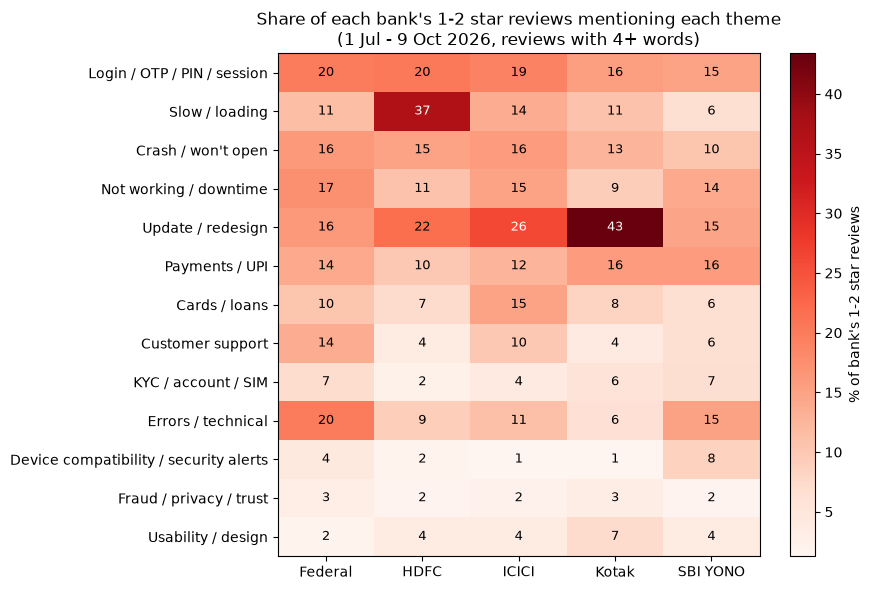

In [30]:
import matplotlib.pyplot as plt

data = by_bank.T
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(data.values, cmap="Reds", aspect="auto")

ax.set_xticks(range(len(data.columns)))
ax.set_xticklabels(data.columns)
ax.set_yticks(range(len(data.index)))
ax.set_yticklabels(data.index)

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="white" if v > 25 else "black", fontsize=9)

ax.set_title("Share of each bank's 1-2 star reviews mentioning each theme\n"
             "(1 Jul - 9 Oct 2026, reviews with 4+ words)")
fig.colorbar(im, label="% of bank's 1-2 star reviews")
plt.tight_layout()
plt.savefig("../outputs/theme_heatmap.png", dpi=200)
plt.show()

## 12. RICE prioritisation (client: HDFC)
Scores each theme by reach (from the data) x impact x confidence / effort (my judgement). Slow / loading ranks first (20.7); Update/redesign (11.3) and Login (10.8) are effectively tied.


In [ ]:
bank = "HDFC"
mine = by_bank.loc[bank]
peers = by_bank.drop(bank).mean()
rice = pd.DataFrame({
    "reach_pct": mine,
    "peer_avg_pct": peers.round(1),
    "gap_pts": (mine - peers).round(1),
}).sort_values("reach_pct", ascending=False).head(6)

rice

,reach_pct,peer_avg_pct,gap_pts
Slow / loading,36.6,10.5,26.1
Update / redesign,21.6,25.1,-3.5
Login / OTP / PIN / session,20.3,17.4,2.9
Crash / won't open,14.9,13.8,1.1
Not working / downtime,10.7,13.8,-3.2
Payments / UPI,10.0,14.6,-4.6


In [32]:
rice["impact"] = [2, 3, 2, 2, 3, 3]       # fill in, one number per row
rice["confidence_pct"] = [85, 90, 80, 75, 85, 80]
rice["effort"] = [2, 4, 3, 3, 4, 5]
rice["RICE"] = (rice["reach_pct"] * rice["impact"] * (rice["confidence_pct"] / 100) / rice["effort"]).round(1)
rice.sort_values("RICE", ascending=False)

,reach_pct,peer_avg_pct,gap_pts,impact,confidence_pct,effort,RICE
Slow / loading,36.6,10.5,26.1,2,85,2,31.1
Update / redesign,21.6,25.1,-3.5,3,90,4,14.6
Login / OTP / PIN / session,20.3,17.4,2.9,2,80,3,10.8
Crash / won't open,14.9,13.8,1.1,2,75,3,7.4
Not working / downtime,10.7,13.8,-3.2,3,85,4,6.8
Payments / UPI,10.0,14.6,-4.6,3,80,5,4.8


In [33]:
import numpy as np
rng = np.random.default_rng(42)

ranges = {  # (impact lo, hi), (confidence lo, hi), (effort lo, hi) for each theme
    "Slow / loading":              ((1, 3), (70, 95), (2, 4)),
    "Update / redesign":           ((2, 3), (55, 85), (3, 5)),
    "Login / OTP / PIN / session": ((1, 3), (65, 90), (2, 4)),
    "Crash / won't open":          ((2, 3), (60, 85), (2, 4)),
    "Not working / downtime":      ((2, 3), (70, 90), (3, 5)),
    "Payments / UPI":              ((2, 3), (65, 90), (3, 5)),
}

N = 10000
scores = {}
for theme, (imp, conf, eff) in ranges.items():
    reach = rice.loc[theme, "reach_pct"]
    i = rng.integers(imp[0], imp[1] + 1, N)
    c = rng.uniform(conf[0], conf[1], N) / 100
    e = rng.integers(eff[0], eff[1] + 1, N)
    scores[theme] = reach * i * c / e

s = pd.DataFrame(scores)
ranks = s.rank(axis=1, ascending=False)
print("Share of simulations where each theme ranks #1:")
print((ranks == 1).mean().mul(100).round(1).sort_values(ascending=False))
print("\nShare where each theme is in the top 3:")
print((ranks <= 3).mean().mul(100).round(1).sort_values(ascending=False))


Share of simulations where each theme ranks #1:
Slow / loading                 69.0
Login / OTP / PIN / session    16.2
Crash / won't open              7.5
Update / redesign               7.1
Not working / downtime          0.1
Payments / UPI                  0.0
dtype: float64

Share where each theme is in the top 3:
Slow / loading                 93.6
Update / redesign              66.5
Login / OTP / PIN / session    64.8
Crash / won't open             62.3
Not working / downtime          8.2
Payments / UPI                  4.6
dtype: float64


## 10. Deep dive: HDFC slowness
Slowness rose from 16% of HDFC's 1-2 star reviews in July to 54% in October. Only about a quarter of slow reviews also mention an update, so slowness is not just the redesign theme under another name.

In [34]:
h = neg[neg["bank"] == "HDFC"]

print("HDFC negative reviews:", len(h))
print("Slow reviews that also mention update/redesign:",
      round(h.loc[h["Slow / loading"], "Update / redesign"].mean() * 100, 1), "%")
print("Update reviews that also mention slow:",
      round(h.loc[h["Update / redesign"], "Slow / loading"].mean() * 100, 1), "%")

monthly = h.groupby("month").agg(
    negative_reviews=("reviewId", "count"),
    slow_pct=("Slow / loading", lambda x: round(x.mean() * 100, 1)),
    update_pct=("Update / redesign", lambda x: round(x.mean() * 100, 1)),
)
monthly

HDFC negative reviews: 2883
Slow reviews that also mention update/redesign: 25.9 %
Update reviews that also mention slow: 43.8 %


,negative_reviews,slow_pct,update_pct
month,,,
2026-07,520,16.2,17.7
2026-08,694,29.3,19.9
2026-09,1037,41.5,23.4
2026-10,632,53.5,23.9


In [35]:
h[h["Slow / loading"]].sample(30, random_state=5)[["score", "content"]]


,score,content
10774,1,worst experience. taking too much time to open...
16253,1,Easily one of the worst mobile banking apps. w...
10472,1,this app is lagging a lot. The older version w...
10492,1,worst banking app. it's just keep loading
10134,1,This app seemed to have a very bad response. N...
11128,1,"very slow, worst app"
10098,1,aap is too slow very bed experience with aap l...
18565,1,running to slow all time..since I use never se...
11699,1,This mobile app is too slow to login. Not the ...
12352,1,App is not opening. it's taking too long time ...


In [36]:
h[h["Slow / loading"]].sample(30, random_state=5)[["score", "content"]]

,score,content
10774,1,worst experience. taking too much time to open...
16253,1,Easily one of the worst mobile banking apps. w...
10472,1,this app is lagging a lot. The older version w...
10492,1,worst banking app. it's just keep loading
10134,1,This app seemed to have a very bad response. N...
11128,1,"very slow, worst app"
10098,1,aap is too slow very bed experience with aap l...
18565,1,running to slow all time..since I use never se...
11699,1,This mobile app is too slow to login. Not the ...
12352,1,App is not opening. it's taking too long time ...


## 11. Slowness by app version
The share mentioning slowness rises from 15% on v9.0.4 to 51% on v11.1.0. Comparing versions within the same month shows 11-13 point gaps in July and August. This shows association with newer releases, not proof that a release caused the slowdown.

In [37]:
h = neg[neg["bank"] == "HDFC"].copy()
h["version"] = h["appVersion"].fillna("unknown")

by_version = h.groupby("version").agg(
    reviews=("reviewId", "count"),
    slow_pct=("Slow / loading", lambda x: round(x.mean() * 100, 1)),
    first_seen=("at", "min"),
).query("reviews >= 80").sort_values("first_seen")
print(by_version)

base = h[h["month"] == "2026-07"]["Slow / loading"].mean()
later = h[h["month"] != "2026-07"]
excess = (later["Slow / loading"].mean() - base) * len(later)
print("\nJuly slow share:", round(base * 100, 1), "%")
print("Slow reviews above the July level (Aug-Oct):", round(excess),
      "=", round(excess / len(h) * 100, 1), "% of all HDFC negative reviews")

         reviews  slow_pct          first_seen
version                                       
9.0.4        326      15.3 2026-07-01 00:09:54
unknown      443      29.8 2026-07-01 10:49:53
10.1.6       377      25.5 2026-07-10 22:24:46
11.0.1       715      39.4 2026-08-10 21:13:00
11.1.0       951      50.8 2026-09-10 15:22:24

July slow share: 16.2 %
Slow reviews above the July level (Aug-Oct): 589 = 20.4 % of all HDFC negative reviews


In [38]:
main = ["9.0.4", "10.1.6", "11.0.1", "11.1.0"]
h["ver_group"] = h["version"].where(h["version"].isin(main), "other/unknown")

within = (h.groupby(["month", "ver_group"])
            .agg(n=("Slow / loading", "size"), slow_pct=("Slow / loading", "mean")))
within["slow_pct"] = (within["slow_pct"] * 100).round(1)
within[within["n"] >= 40]

n  slow_pct
month   ver_group                   
2026-07 10.1.6         108      25.0
        9.0.4          273      13.9
        other/unknown  139      13.7
2026-08 10.1.6         261      25.3
        11.0.1         282      37.9
        other/unknown  116      20.7
2026-09 11.0.1         426      40.4
        11.1.0         426      46.2
        other/unknown  165      32.7
2026-10 11.1.0         525      54.5
        other/unknown   94      50.0

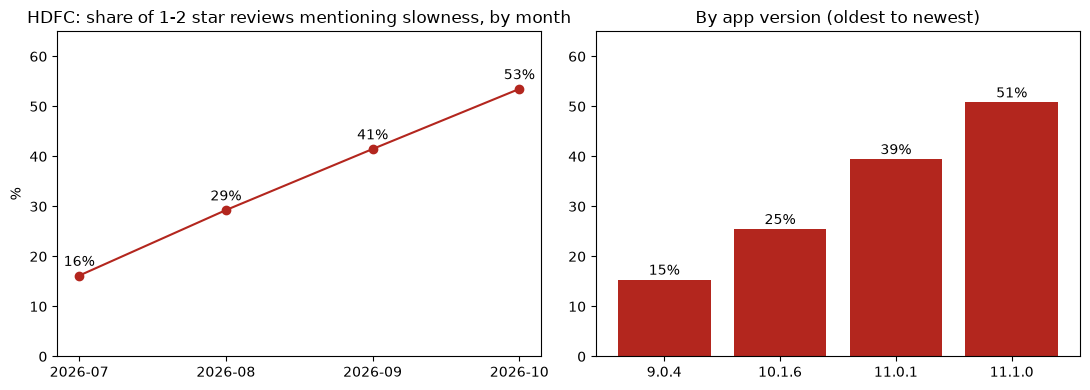

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

m = h.groupby("month")["Slow / loading"].mean().mul(100)
axes[0].plot(m.index, m.values, marker="o", color="#b3261e")
axes[0].set_title("HDFC: share of 1-2 star reviews mentioning slowness, by month")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 65)
for x, y in zip(m.index, m.values):
    axes[0].annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 7), ha="center")

v = h[h["version"].isin(main)].groupby("version")["Slow / loading"].mean().mul(100).reindex(main)
axes[1].bar(v.index, v.values, color="#b3261e")
axes[1].set_title("By app version (oldest to newest)")
axes[1].set_ylim(0, 65)
for i, y in enumerate(v.values):
    axes[1].text(i, y + 1, f"{y:.0f}%", ha="center")

plt.tight_layout()
plt.savefig("../outputs/hdfc_slowness_trend.png", dpi=200)
plt.show()

## 14. Save results
Writes the result tables and charts to the outputs folder.

In [40]:
by_bank.round(1).to_csv("../outputs/theme_share_by_bank.csv")
rice.sort_values("RICE", ascending=False).to_csv("../outputs/hdfc_rice.csv")
monthly.to_csv("../outputs/hdfc_monthly_slowness.csv")
within[within["n"] >= 40].to_csv("../outputs/hdfc_slowness_by_version_month.csv")

## 13. Sensitivity test
Reruns the ranking 10,000 times with impact, confidence and effort varied across plausible ranges. Slow / loading ranks first in 69% of runs.

In [41]:
rice["confidence_pct"] = [85, 70, 80, 75, 85, 80]   # Update/redesign now 70
rice["effort"]         = [3, 4, 3, 3, 4, 5]          # Slow/loading now 3
rice["RICE"] = (rice["reach_pct"] * rice["impact"] * (rice["confidence_pct"] / 100)
                / rice["effort"]).round(1)
rice = rice.sort_values("RICE", ascending=False)
rice.to_csv("../outputs/hdfc_rice_final.csv")
rice

,reach_pct,peer_avg_pct,gap_pts,impact,confidence_pct,effort,RICE
Slow / loading,36.6,10.5,26.1,2,85,3,20.7
Update / redesign,21.6,25.1,-3.5,3,70,4,11.3
Login / OTP / PIN / session,20.3,17.4,2.9,2,80,3,10.8
Crash / won't open,14.9,13.8,1.1,2,75,3,7.4
Not working / downtime,10.7,13.8,-3.2,3,85,4,6.8
Payments / UPI,10.0,14.6,-4.6,3,80,5,4.8
